A notebook to test the functions of the new vrdr_resampler Python module.

In [2]:
# auto reload
%load_ext autoreload
%autoreload 2

In [3]:
import vrdr_resampler as vrdr
from pathlib import Path

# Loading the CaSSIS Spectral Response

Setting a string id for the instrument, that will prefixed to output files:

In [4]:
inst_id = 'c'

Setting the path to the instrument file:

In [5]:
# instrument path
inst_path = Path('instrument_response', 'CaSSIS-2019.csv')

Loading instrument transmission profiles:

In [6]:
cassis_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(cassis_data)

Checking the profile spectral range and resolution:

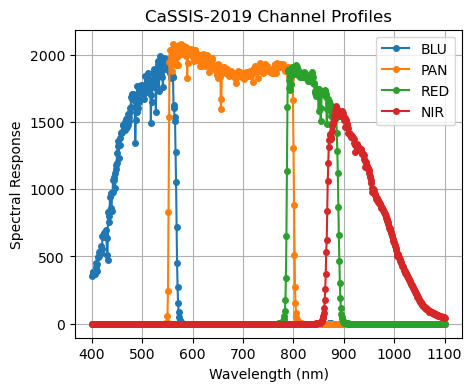

In [7]:
fig, ax = vrdr.plot_channel_profiles(cassis_data, instrument='CaSSIS-2019')

# Loading a VRDR Tile

Setting the data directory:

In [8]:
vrdr_path = Path('/Volumes', 'VRDR_STORE', 'vrdr')

Setting the output directory:

In [9]:
output_path = vrdr_path.parent / 'vrdr_cassis'
output_path.mkdir(exist_ok=True) 

Finding the quadrant directories:

In [10]:
mc_paths = vrdr.get_quadrant_dirs(vrdr_path)
mc_path = mc_paths[-3]  # Example: process the first quadrant directory

In [11]:
# get mc13
mc_path = [q for q in mc_paths if 'mc13' in q.stem][0]

In [12]:
mc_path

PosixPath('/Volumes/VRDR_STORE/vrdr/mc13')

Finding the tile paths in the quadrant directory:

In [13]:
lbl_paths = vrdr.get_tile_lbls(mc_path)
lbl_path = lbl_paths[29]  # Example: process the first label file

In [14]:
# get the lbl_path that has 't1250' in the name
lbl_path = [p for p in lbl_paths if 't1250' in p.stem][0]
lbl_path

PosixPath('/Volumes/VRDR_STORE/vrdr/mc13/t1250_vrral_20n078_0654_1.lbl')

Preparing the output file directory:

In [15]:
out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=True)
out_dir

Output directory exists, overwriting:  /Volumes/VRDR_STORE/vrdr_cassis/mc13/t1250_vrral_20n078_0654_1


PosixPath('/Volumes/VRDR_STORE/vrdr_cassis/mc13/t1250_vrral_20n078_0654_1')

Loading the tile, getting the band centre-wavelengths, and the no-data value:

In [16]:
vrdr_cube, vrdr_cwls, no_data = vrdr.load_vrdr_tile(lbl_path)

# Resampling to the Spectral Response to a CaSSIS I/F Cube

Resampling the VRDR Cube from the VRDR CWLs to the instrument bands:

In [17]:
cifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_cwls, no_data)

# Exporting the I/F Cube

In [ ]:
out_file = vrdr.export_ifcub_geotiff(cifcub,band_list,band_cwls,no_data,inst_id,lbl_path,out_dir)
out_hdr = vrdr.write_ifcub_envi_hdr(band_list, band_cwls, no_data,[4,2,1], inst_id, lbl_path, out_dir)

/opt/homebrew/Caskroom/miniconda/base/envs/vrdr_resampler/lib/python3.14/site-packages/osgeo/gdal.py:311: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


## Verifying the Resampling Method

Checking the interpolation of the band wavelengths to the VRDR CWLs:

In [18]:
b_w = arr_wvls
c_w = vrdr_cwls
b_a = band_arr
resampled_profiles = [vrdr.interp_band_profile(b_p, b_w, c_w) for b_p in b_a.T]

In [19]:
import numpy as np
import pandas as pd
resampled_inst = pd.DataFrame(data=np.array(resampled_profiles).T, columns=band_list, index=c_w)

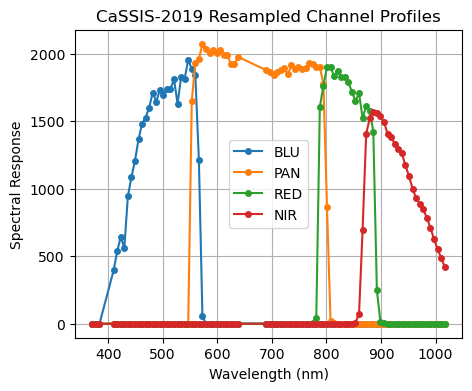

In [20]:
fig, ax = vrdr.plot_channel_profiles(resampled_inst, instrument='CaSSIS-2019 Resampled')

Checking a random selection of VRDR tile spectra

In [21]:
resampled_inst

,BLU,PAN,RED,NIR
371.12,0.000000,0.000000,0.000000,0.000000
377.62,0.000000,0.000000,0.000000,0.000000
384.12,0.000000,0.000000,0.000000,0.000000
410.12,396.592400,0.014239,0.043022,0.000000
416.62,537.023143,0.028106,0.026392,0.133103
...,...,...,...,...
990.55,0.172807,0.028862,0.164288,711.052426
997.10,0.199571,0.033724,0.169817,627.483366
1003.64,0.164489,0.000352,0.117013,553.841711
1010.18,0.176548,0.001507,0.102619,488.012018


In [49]:
# select random locations in the last 2 dimensions of the cube
import random
import matplotlib.pyplot as plt

num_samples = 8
x_size, y_size = vrdr_cube.shape[1], vrdr_cube.shape[2]

random_coords = [(random.randint(0, x_size - 1), random.randint(0, y_size - 1)) for _ in range(num_samples)]


In [50]:
random_coords

[(2233, 2431),
 (684, 2874),
 (1461, 2007),
 (632, 2362),
 (2503, 705),
 (1590, 1627),
 (2898, 1516),
 (2833, 2567)]

In [54]:
# random_coords_1 = random_coords
random_coords_1

[(2233, 2431),
 (684, 2874),
 (1461, 2007),
 (632, 2362),
 (2503, 705),
 (1590, 1627),
 (2898, 1516),
 (2833, 2567)]

#9467bd
#8c564b
#e377c2
#7f7f7f
#bcbd22
#17becf
#1f77b4
#ff7f0e


/var/folders/w4/44k32f413dd82lxmtw9456w80000gp/T/ipykernel_20118/3309450907.py:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/w4/44k32f413dd82lxmtw9456w80000gp/T/ipykernel_20118/3309450907.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_ctx.show()


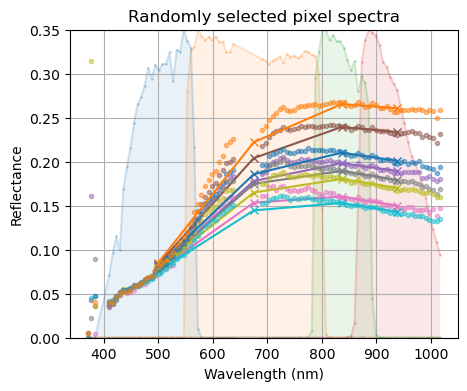

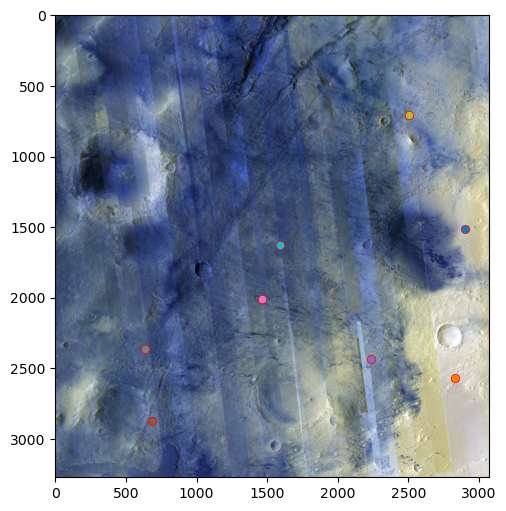

In [76]:

fig, ax = plt.subplots(figsize=(5, 4))

# show the source tile with the randomly selected pixel locations indicated
fig_ctx, ax_ctx = plt.subplots(figsize=(8, 6))

ax_ctx.imshow(bp)



y_max = 0.35

for band in resampled_inst.columns:
    ax.plot(resampled_inst.index, y_max*resampled_inst[band]/np.nanmax(resampled_inst[band]), label=band, linestyle='-',marker='o', alpha=0.2, markersize=1)
    # fill the area under each band profile
    ax.fill_between(resampled_inst.index, 0, y_max*resampled_inst[band]/np.nanmax(resampled_inst[band]), alpha=0.1)

for x, y in random_coords:
    vrdr_spectrum = vrdr_cube[:, x, y]
    cassis_spectrum = cifcub[:, x, y]

    ax.plot(vrdr_cwls, vrdr_spectrum, label=f'{x,y}', marker='o', markersize=3, linestyle='None', alpha=0.5)
    # get colour used in the plot above
    color = ax.get_lines()[-1].get_color()
    ax.plot(band_cwls, cassis_spectrum, label=f'{x,y}', marker='x', markersize=6, color=color)
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Reflectance')
    print(color)

    ax_ctx.plot(x, y, 'o', color=color, markeredgecolor='red', markeredgewidth=0.5)  # mark the random coordinates

# plt.legend()
ax.set_title(f'Randomly selected pixel spectra')
ax.set_ylim(0, y_max)
ax.grid()
fig.show()

fig_ctx.show()

# save the figure as a svg
fig.savefig('random_pixel_spectra.svg', format='svg', dpi=600)
fig_ctx.savefig('random_pixel_locations.svg', format='svg', dpi=600)

In [63]:
st_cub, st_params = vrdr.stretch_cube(cifcub, no_data)
for bp_id in [cassis.BP_LIST[0]]:
    bp_func = cassis.browse_product(bp_id)
    bp, bp_bands = bp_func(st_cub)

In [64]:
bp_id

'NPB'

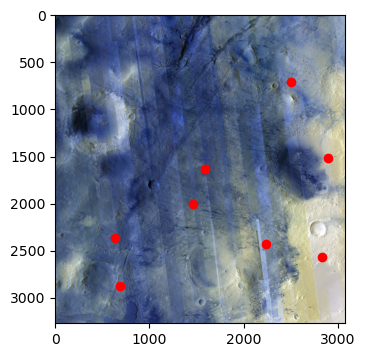

In [ ]:
# show the source tile with the randomly selected pixel locations indicated
fig, ax = plt.subplots(figsize=(5, 4))

ax.imshow(bp)

ax.plot([coord[0] for coord in random_coords], [coord[1] for coord in random_coords], 'ro')  # mark the random coordinates with red dots
plt.show()

Note that data points with wavelengths <400 nm (i.e. the apparently noisy channels) are 0-weighted by the CaSSIS BLU transmission, so they effectively are not counted.

# Prepare Products

Import the instrument specific product class:

In [59]:
import cassis_products as cassis

## Spectral Parameter (or Summary Product) Stack

Make a stack of the spectral parameters:

In [22]:
cspcub, sp_ids = cassis.spectral_parameter_stack(cifcub, no_data)

Export the stack to a GeoTIFF:

In [23]:
vrdr.export_spcub_geotiff(cspcub,sp_ids,no_data,inst_id,lbl_path,out_dir)

PosixPath('/Volumes/VRDR_STORE/vrdr_cassis/mc28/t0313_vrral_45s073_0654_1/t0313_cspcub_45s073_0654_1.tif')

In [24]:
vrdr.write_spcub_envi_hdr(sp_ids, no_data, [3, 1, 2],inst_id,lbl_path,out_dir)

PosixPath('/Volumes/VRDR_STORE/vrdr_cassis/mc28/t0313_vrral_45s073_0654_1/t0313_cspcub_45s073_0654_1.hdr')

## Browse Products

Stretching the I/F Cube: stretching float I/F data to 8-bit unsigned int for efficient browse product storage involves stretching each channel.

The standard method for CaSSIS is to use percentile stretches, where the bottom 0.1% and the top 99.95% percentiles are used to set the clip values.

We log these stretch parameters.

In [61]:
mc_path

PosixPath('/Volumes/VRDR_STORE/vrdr/mc13')

In [62]:
lbl_path

PosixPath('/Volumes/VRDR_STORE/vrdr/mc13/t1250_vrral_20n078_0654_1.lbl')

In [27]:
i=34

34


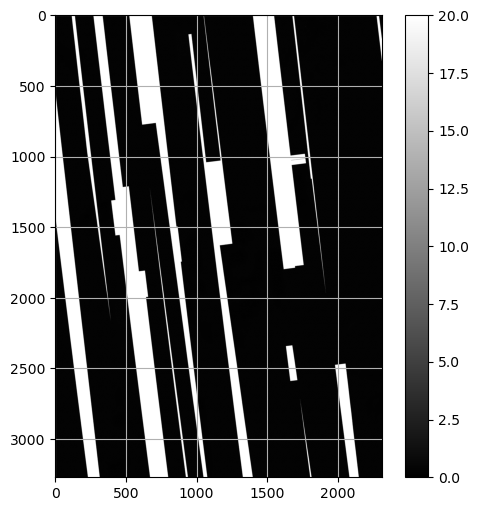

In [28]:
fig, ax = plt.subplots(figsize=(6,6))
print(i)
pos=ax.imshow(cifcub[2,:,:], cmap='gray', vmin=0, vmax=20)
fig.colorbar(pos, ax=ax)
ax.grid()


In [29]:
i=0

0


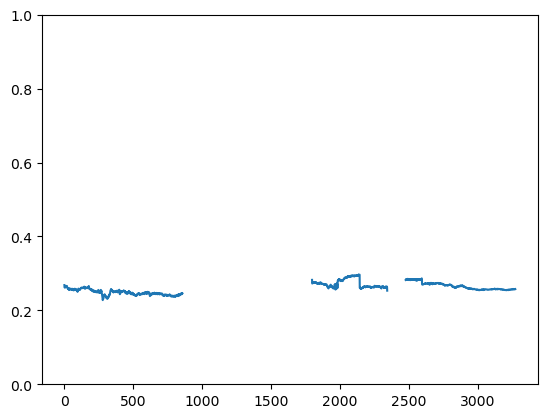

In [30]:
print(i)
slice = cifcub[2,:,1650+i].copy()
# where slice > 1.0, set to nan
slice[slice > 4.0] = np.nan
plt.plot(slice)
plt.ylim(0, 1.0)
i+=1

In [31]:
st_cub, st_params = vrdr.stretch_cube(cifcub, no_data)

In [32]:
st_params

array([[0.08583405, 0.17399238, 0.19162929, 0.18396832],
       [0.12467699, 0.27934328, 0.326179  , 0.32234527]])

In [33]:
log_path = vrdr.log_st_params(st_params, band_list, lbl_path, out_dir)

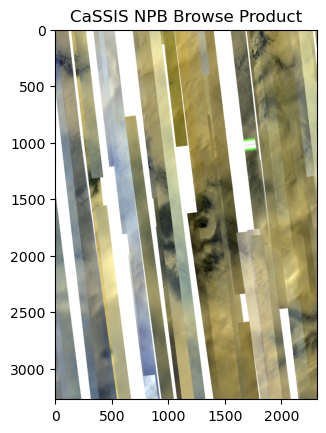

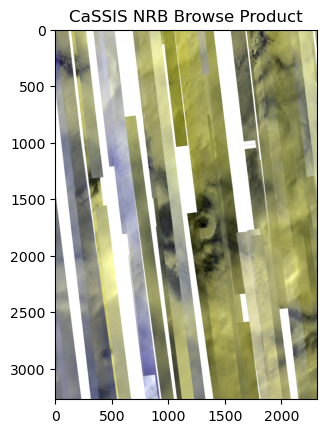

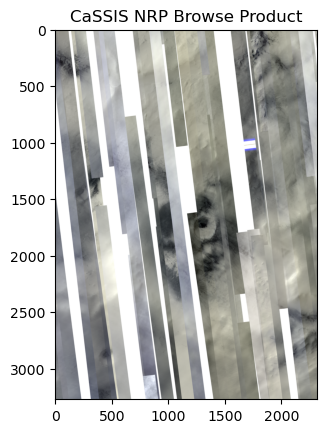

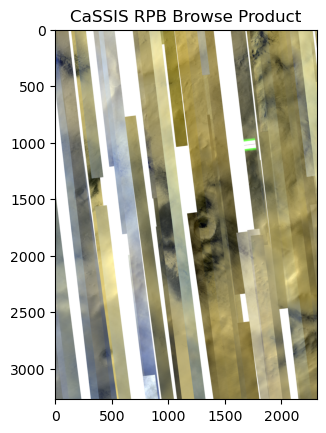

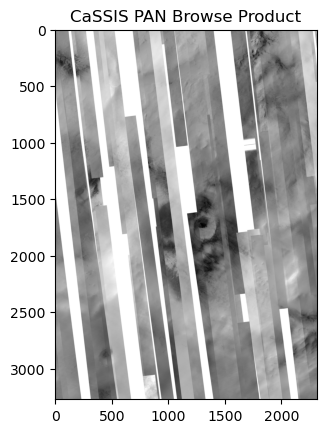

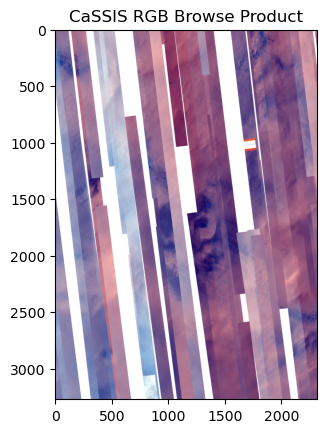

In [34]:
cifcub_mod = cassis.cassis_add_sblu(cifcub, no_data)
st_cub, st_params = vrdr.stretch_cube(cifcub_mod, no_data)
for bp_id in cassis.BP_LIST:
    bp_func = cassis.browse_product(bp_id)
    bp, bp_bands = bp_func(st_cub)
    vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, inst_id, lbl_path, out_dir)
    plt.imshow(bp)
    plt.title(f'CaSSIS {bp_id} Browse Product')
    plt.show()

## Composite Spectral Parameter Browse Products

[[0.69441333 1.9304369  0.83852079]
 [1.20368172 2.57126333 1.02899877]]


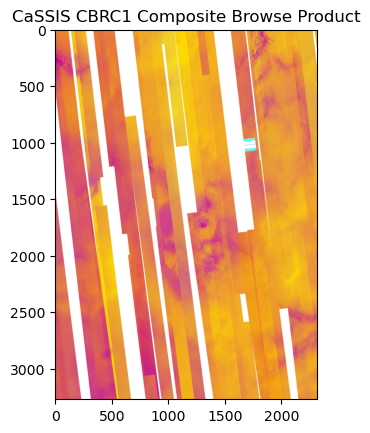

[[0.69441333 1.9304369  0.07242392]
 [1.20368172 2.57126333 0.10410066]]


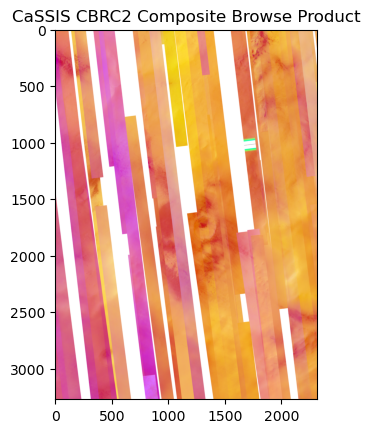

In [35]:
for cp_id in cassis.CP_LIST:
    cp_func = cassis.composite_product(cp_id)
    cp, cp_list = cp_func(cifcub, no_data)
    cp_st, st_params = vrdr.stretch_cube(cp, no_data)
    print(st_params)
    vrdr.export_bp_geotiff(cp_st.transpose((1, 2, 0)), cp_id, 255, cp_list, inst_id, lbl_path, out_dir)
    plt.imshow(cp_st.transpose((1, 2, 0)))
    plt.title(f'CaSSIS {cp_id} Composite Browse Product')
    plt.show()

# Running the Loop

In [36]:
from tqdm.auto import tqdm

In [38]:
vrdr_path = Path('/Volumes', 'VRDR_STORE', 'vrdr')
output_path = vrdr_path.parent / 'vrdr_cassis'
output_path.mkdir(exist_ok=True) 

inst_id = 'c'
inst_path = Path('instrument_response', 'CaSSIS-2019.csv')
cassis_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(cassis_data)

mc_paths = vrdr.get_quadrant_dirs(vrdr_path)

log_file = open(output_path / 'processing_log.txt', 'w')

for mc_path in tqdm(mc_paths, desc='Quadrants'):
    # if mc_path.stem not in ['mc16']:
    #     continue
    print('Processing MC Directory: ', mc_path.name)
    log_file.write(f'Processing MC Directory: {mc_path.name}\n')
    # get lbl files but ignore hidden files
    lbl_paths = vrdr.get_tile_lbls(mc_path)
    # sort

    for lbl_path in tqdm(lbl_paths, desc=f'{mc_path.stem} Tiles'):
        print(' - ', lbl_path.stem)
        log_file.write(f' - Processing Tile: {lbl_path.stem}\n')

        out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=False)
        if out_dir == Path():
            print('   ! Output directory exists and overwrite is False. Skipping file.')
            log_file.write('   ! Output directory exists and overwrite is False. Skipping file.\n')
            continue

        vrdr_cube, vrdr_wvls, no_data = vrdr.load_vrdr_tile(lbl_path)

        if vrdr_cube is None:
            print('   ! Skipping Tile due to read error.')
            log_file.write('   ! Skipping Tile due to read error.\n')
            continue

        cifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_wvls, no_data)

        out_file = vrdr.export_ifcub_geotiff(cifcub, band_list, band_cwls, no_data, inst_id, lbl_path, out_dir)
        out_hdr = vrdr.write_ifcub_envi_hdr(band_list, band_cwls, no_data, [4, 2, 1], inst_id, lbl_path, out_dir)

        st_cub, st_params = vrdr.stretch_cube(cifcub, no_data)
        log_path = vrdr.log_st_params(st_params, band_list, lbl_path, out_dir)

        cspcub, sp_ids = cassis.spectral_parameter_stack(cifcub, no_data)
        vrdr.export_spcub_geotiff(cspcub,sp_ids,no_data,inst_id,lbl_path,out_dir)
        vrdr.write_spcub_envi_hdr(sp_ids, no_data, [3, 1, 2],inst_id,lbl_path,out_dir)

        cifcub_mod = cassis.cassis_add_sblu(cifcub, no_data)
        st_cub, st_params = vrdr.stretch_cube(cifcub_mod, no_data)
        for bp_id in cassis.BP_LIST:
            bp_func = cassis.browse_product(bp_id)
            bp, bp_bands = bp_func(st_cub)
            vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, inst_id, lbl_path, out_dir)

        for cp_id in cassis.CP_LIST:
            cp_func = cassis.composite_product(cp_id)
            cp, cp_list = cp_func(cifcub, no_data)
            cp_st, st_params = vrdr.stretch_cube(cp, no_data)
            vrdr.export_bp_geotiff(cp_st.transpose((1, 2, 0)), cp_id, 255, cp_list, inst_id, lbl_path, out_dir)
log_file.close()        

Quadrants:   0%|          | 0/29 [00:00<?, ?it/s]

Processing MC Directory:  mc02


mc02 Tiles:   0%|          | 0/69 [00:00<?, ?it/s]

 -  t1487_vrral_35n183_0654_1
 -  t1488_vrral_35n188_0654_1
 -  t1489_vrral_35n193_0654_1
 -  t1490_vrral_35n198_0654_1
 -  t1491_vrral_35n203_0654_1
 -  t1492_vrral_35n208_0654_1
 -  t1493_vrral_35n213_0654_1
 -  t1494_vrral_35n218_0654_1
 -  t1495_vrral_35n223_0654_1
 -  t1496_vrral_35n228_0654_1
 -  t1497_vrral_35n233_0654_1
 -  t1498_vrral_35n238_0654_1
 -  t1559_vrral_40n183_0654_1
 -  t1560_vrral_40n188_0654_1
 -  t1561_vrral_40n193_0654_1
 -  t1562_vrral_40n198_0654_1
 -  t1563_vrral_40n203_0654_1
 -  t1564_vrral_40n208_0654_1
 -  t1565_vrral_40n213_0654_1
 -  t1566_vrral_40n218_0654_1
 -  t1567_vrral_40n223_0654_1
 -  t1568_vrral_40n228_0654_1
 -  t1569_vrral_40n233_0654_1
 -  t1570_vrral_40n238_0654_1
 -  t1631_vrral_45n183_0654_1
 -  t1632_vrral_45n188_0654_1
 -  t1633_vrral_45n193_0654_1
 -  t1634_vrral_45n198_0654_1
 -  t1635_vrral_45n203_0654_1
 -  t1636_vrral_45n208_0654_1
 -  t1637_vrral_45n213_0654_1
 -  t1638_vrral_45n218_0654_1
 -  t1639_vrral_45n223_0654_1
 -  t1640_

mc03 Tiles:   0%|          | 0/69 [00:00<?, ?it/s]

 -  t1499_vrral_35n243_0654_1
 -  t1500_vrral_35n248_0654_1
 -  t1501_vrral_35n253_0654_1
 -  t1502_vrral_35n258_0654_1
 -  t1503_vrral_35n263_0654_1
 -  t1504_vrral_35n268_0654_1
 -  t1505_vrral_35n273_0654_1
 -  t1506_vrral_35n278_0654_1
 -  t1507_vrral_35n283_0654_1
 -  t1508_vrral_35n288_0654_1
 -  t1509_vrral_35n293_0654_1
 -  t1510_vrral_35n298_0654_1
 -  t1571_vrral_40n243_0654_1
 -  t1572_vrral_40n248_0654_1
 -  t1573_vrral_40n253_0654_1
 -  t1574_vrral_40n258_0654_1
 -  t1575_vrral_40n263_0654_1
 -  t1576_vrral_40n268_0654_1
 -  t1577_vrral_40n273_0654_1
 -  t1578_vrral_40n278_0654_1
 -  t1579_vrral_40n283_0654_1
 -  t1580_vrral_40n288_0654_1
 -  t1581_vrral_40n293_0654_1
 -  t1582_vrral_40n298_0654_1
 -  t1643_vrral_45n243_0654_1
 -  t1644_vrral_45n248_0654_1
 -  t1645_vrral_45n253_0654_1
 -  t1646_vrral_45n258_0654_1
 -  t1647_vrral_45n263_0654_1
 -  t1648_vrral_45n268_0654_1
 -  t1649_vrral_45n273_0654_1
 -  t1650_vrral_45n278_0654_1
 -  t1651_vrral_45n283_0654_1
 -  t1652_

... (50 outputs left out)

mc29 Tiles:   0%|          | 0/75 [00:00<?, ?it/s]

 -  t0155_vrral_60s123_0654_1
 -  t0156_vrral_60s130_0654_1
 -  t0157_vrral_60s137_0654_1
 -  t0158_vrral_60s143_0654_1
 -  t0159_vrral_60s150_0654_1
 -  t0160_vrral_60s157_0654_1
 -  t0161_vrral_60s163_0654_1
 -  t0162_vrral_60s170_0654_1
 -  t0163_vrral_60s177_0654_1
 -  t0209_vrral_55s123_0654_1
 -  t0210_vrral_55s130_0654_1
 -  t0211_vrral_55s137_0654_1
 -  t0212_vrral_55s143_0654_1
 -  t0213_vrral_55s150_0654_1
 -  t0214_vrral_55s157_0654_1
 -  t0215_vrral_55s163_0654_1
 -  t0216_vrral_55s170_0654_1
 -  t0217_vrral_55s177_0654_1
 -  t0263_vrral_50s123_0654_1
 -  t0264_vrral_50s130_0654_1
 -  t0265_vrral_50s137_0654_1
 -  t0266_vrral_50s143_0654_1
 -  t0267_vrral_50s150_0654_1
 -  t0268_vrral_50s157_0654_1
 -  t0269_vrral_50s163_0654_1
 -  t0270_vrral_50s170_0654_1
 -  t0271_vrral_50s177_0654_1
 -  t0323_vrral_45s123_0654_1
 -  t0324_vrral_45s128_0654_1
 -  t0325_vrral_45s133_0654_1
 -  t0326_vrral_45s138_0654_1
 -  t0327_vrral_45s143_0654_1
 -  t0328_vrral_45s148_0654_1
 -  t0329_

mc30 Tiles:   0%|          | 0/36 [00:00<?, ?it/s]

 -  t0101_vrral_65s005_0654_1
 -  t0102_vrral_65s015_0654_1
 -  t0103_vrral_65s025_0654_1
 -  t0104_vrral_65s035_0654_1
 -  t0105_vrral_65s045_0654_1
 -  t0106_vrral_65s055_0654_1
 -  t0107_vrral_65s065_0654_1
 -  t0108_vrral_65s075_0654_1
 -  t0109_vrral_65s085_0654_1
 -  t0110_vrral_65s095_0654_1
 -  t0111_vrral_65s105_0654_1
 -  t0112_vrral_65s115_0654_1
 -  t0113_vrral_65s125_0654_1
 -  t0114_vrral_65s135_0654_1
 -  t0115_vrral_65s145_0654_1
 -  t0116_vrral_65s155_0654_1
 -  t0117_vrral_65s165_0654_1
 -  t0118_vrral_65s175_0654_1
 -  t0119_vrral_65s185_0654_1
 -  t0120_vrral_65s195_0654_1
 -  t0121_vrral_65s205_0654_1
 -  t0122_vrral_65s215_0654_1
 -  t0123_vrral_65s225_0654_1
 -  t0124_vrral_65s235_0654_1
 -  t0125_vrral_65s245_0654_1
 -  t0126_vrral_65s255_0654_1
 -  t0127_vrral_65s265_0654_1
 -  t0128_vrral_65s275_0654_1
 -  t0129_vrral_65s285_0654_1
 -  t0130_vrral_65s295_0654_1
 -  t0131_vrral_65s305_0654_1
 -  t0132_vrral_65s315_0654_1
 -  t0133_vrral_65s325_0654_1
 -  t0134_

Now I'd like a quick script that loops over all processed tiles in a quadrant, gets the quadrant-wide stretch parameters, and then makes a mosaic browse product at that level.

# Making Quadrant Wide Mosaics

Let's re-write this from scratch, now loading in the .log file from each porcessed mosaic, and putting the new stretch products in a dedicated new product directory (vrdr_cassis_quads).

In [40]:
# get cassis quadrant directory paths
vrdr_cassis_path = Path('/Volumes', 'VRDR_STORE', 'vrdr_cassis')
vrdr_path = Path('/Volumes', 'VRDR_STORE', 'vrdr') # still need to go back and get the orig. label files
output_path = vrdr_cassis_path.parent / 'vrdr_cassis_quads'
output_path.mkdir(exist_ok=True) 

mc_paths = vrdr.get_quadrant_dirs(vrdr_cassis_path)

for mc_path in tqdm(mc_paths, desc='Quadrants'):
    print('Processing MC Directory: ', mc_path.name)
    tile_paths = vrdr.get_tile_dirs(mc_path)

    quad_st_params = vrdr.get_quadrant_stretch_params(tile_paths)

    for tile_path in tqdm(tile_paths, desc='Tiles'):
        print(' - ', tile_path.stem)
        # get tiff files
        orig_tile_path = vrdr_path / mc_path.stem / tile_path.stem
        lbl_path = Path(orig_tile_path).with_suffix('.lbl')

        out_dir = output_path / mc_path.stem
        out_dir.mkdir(parents=True, exist_ok=True)

        # read the cifcub
        cube_file = [f for f in tile_path.glob('*cifcub*.tif')][0]
        cifcub, no_data = vrdr.read_geotiff_cube(cube_file)

        st_cub, st_params = vrdr.stretch_cube(cifcub, no_data, st_params=quad_st_params)
        
        bp_list = cassis.BP_LIST.copy()
        bp_list.remove('RGB')
        for bp_id in bp_list:
            bp, bp_bands = cassis.browse_product(bp_id)(st_cub)
            vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, inst_id, lbl_path, out_dir/bp_id, 'quadrant')

    log_file = vrdr.log_st_params(quad_st_params, band_list, lbl_path, out_dir)


Quadrants:   0%|          | 0/29 [00:00<?, ?it/s]

Processing MC Directory:  mc02


Tiles:   0%|          | 0/69 [00:00<?, ?it/s]

 -  t1487_vrral_35n183_0654_1
 -  t1488_vrral_35n188_0654_1
 -  t1489_vrral_35n193_0654_1
 -  t1490_vrral_35n198_0654_1
 -  t1491_vrral_35n203_0654_1
 -  t1492_vrral_35n208_0654_1
 -  t1493_vrral_35n213_0654_1
 -  t1494_vrral_35n218_0654_1
 -  t1495_vrral_35n223_0654_1
 -  t1496_vrral_35n228_0654_1
 -  t1497_vrral_35n233_0654_1
 -  t1498_vrral_35n238_0654_1
 -  t1559_vrral_40n183_0654_1
 -  t1560_vrral_40n188_0654_1
 -  t1561_vrral_40n193_0654_1
 -  t1562_vrral_40n198_0654_1
 -  t1563_vrral_40n203_0654_1
 -  t1564_vrral_40n208_0654_1
 -  t1565_vrral_40n213_0654_1
 -  t1566_vrral_40n218_0654_1
 -  t1567_vrral_40n223_0654_1
 -  t1568_vrral_40n228_0654_1
 -  t1569_vrral_40n233_0654_1
 -  t1570_vrral_40n238_0654_1
 -  t1631_vrral_45n183_0654_1
 -  t1632_vrral_45n188_0654_1
 -  t1633_vrral_45n193_0654_1
 -  t1634_vrral_45n198_0654_1
 -  t1635_vrral_45n203_0654_1
 -  t1636_vrral_45n208_0654_1
 -  t1637_vrral_45n213_0654_1
 -  t1638_vrral_45n218_0654_1
 -  t1639_vrral_45n223_0654_1
 -  t1640_

Tiles:   0%|          | 0/69 [00:00<?, ?it/s]

 -  t1499_vrral_35n243_0654_1
 -  t1500_vrral_35n248_0654_1
 -  t1501_vrral_35n253_0654_1
 -  t1502_vrral_35n258_0654_1
 -  t1503_vrral_35n263_0654_1
 -  t1504_vrral_35n268_0654_1
 -  t1505_vrral_35n273_0654_1
 -  t1506_vrral_35n278_0654_1
 -  t1507_vrral_35n283_0654_1
 -  t1508_vrral_35n288_0654_1
 -  t1509_vrral_35n293_0654_1
 -  t1510_vrral_35n298_0654_1
 -  t1571_vrral_40n243_0654_1
 -  t1572_vrral_40n248_0654_1
 -  t1573_vrral_40n253_0654_1
 -  t1574_vrral_40n258_0654_1
 -  t1575_vrral_40n263_0654_1
 -  t1576_vrral_40n268_0654_1
 -  t1577_vrral_40n273_0654_1
 -  t1578_vrral_40n278_0654_1
 -  t1579_vrral_40n283_0654_1
 -  t1580_vrral_40n288_0654_1
 -  t1581_vrral_40n293_0654_1
 -  t1582_vrral_40n298_0654_1
 -  t1643_vrral_45n243_0654_1
 -  t1644_vrral_45n248_0654_1
 -  t1645_vrral_45n253_0654_1
 -  t1646_vrral_45n258_0654_1
 -  t1647_vrral_45n263_0654_1
 -  t1648_vrral_45n268_0654_1
 -  t1649_vrral_45n273_0654_1
 -  t1650_vrral_45n278_0654_1
 -  t1651_vrral_45n283_0654_1
 -  t1652_

... (50 outputs left out)

Tiles:   0%|          | 0/75 [00:00<?, ?it/s]

 -  t0155_vrral_60s123_0654_1
 -  t0156_vrral_60s130_0654_1
 -  t0157_vrral_60s137_0654_1
 -  t0158_vrral_60s143_0654_1
 -  t0159_vrral_60s150_0654_1
 -  t0160_vrral_60s157_0654_1
 -  t0161_vrral_60s163_0654_1
 -  t0162_vrral_60s170_0654_1
 -  t0163_vrral_60s177_0654_1
 -  t0209_vrral_55s123_0654_1
 -  t0210_vrral_55s130_0654_1
 -  t0211_vrral_55s137_0654_1
 -  t0212_vrral_55s143_0654_1
 -  t0213_vrral_55s150_0654_1
 -  t0214_vrral_55s157_0654_1
 -  t0215_vrral_55s163_0654_1
 -  t0216_vrral_55s170_0654_1
 -  t0217_vrral_55s177_0654_1
 -  t0263_vrral_50s123_0654_1
 -  t0264_vrral_50s130_0654_1
 -  t0265_vrral_50s137_0654_1
 -  t0266_vrral_50s143_0654_1
 -  t0267_vrral_50s150_0654_1
 -  t0268_vrral_50s157_0654_1
 -  t0269_vrral_50s163_0654_1
 -  t0270_vrral_50s170_0654_1
 -  t0271_vrral_50s177_0654_1
 -  t0323_vrral_45s123_0654_1
 -  t0324_vrral_45s128_0654_1
 -  t0325_vrral_45s133_0654_1
 -  t0326_vrral_45s138_0654_1
 -  t0327_vrral_45s143_0654_1
 -  t0328_vrral_45s148_0654_1
 -  t0329_

Tiles:   0%|          | 0/36 [00:00<?, ?it/s]

 -  t0101_vrral_65s005_0654_1
 -  t0102_vrral_65s015_0654_1
 -  t0103_vrral_65s025_0654_1
 -  t0104_vrral_65s035_0654_1
 -  t0105_vrral_65s045_0654_1
 -  t0106_vrral_65s055_0654_1
 -  t0107_vrral_65s065_0654_1
 -  t0108_vrral_65s075_0654_1
 -  t0109_vrral_65s085_0654_1
 -  t0110_vrral_65s095_0654_1
 -  t0111_vrral_65s105_0654_1
 -  t0112_vrral_65s115_0654_1
 -  t0113_vrral_65s125_0654_1
 -  t0114_vrral_65s135_0654_1
 -  t0115_vrral_65s145_0654_1
 -  t0116_vrral_65s155_0654_1
 -  t0117_vrral_65s165_0654_1
 -  t0118_vrral_65s175_0654_1
 -  t0119_vrral_65s185_0654_1
 -  t0120_vrral_65s195_0654_1
 -  t0121_vrral_65s205_0654_1
 -  t0122_vrral_65s215_0654_1
 -  t0123_vrral_65s225_0654_1
 -  t0124_vrral_65s235_0654_1
 -  t0125_vrral_65s245_0654_1
 -  t0126_vrral_65s255_0654_1
 -  t0127_vrral_65s265_0654_1
 -  t0128_vrral_65s275_0654_1
 -  t0129_vrral_65s285_0654_1
 -  t0130_vrral_65s295_0654_1
 -  t0131_vrral_65s305_0654_1
 -  t0132_vrral_65s315_0654_1
 -  t0133_vrral_65s325_0654_1
 -  t0134_

# Making Global Stretch Tiles

In [41]:
# get cassis tile directory paths
vrdr_cassis_path = Path('/Volumes', 'VRDR_STORE', 'vrdr_cassis')
vrdr_path = Path('/Volumes', 'VRDR_STORE', 'vrdr') # still need to go back and get the orig. label files
mc_paths = vrdr.get_quadrant_dirs(vrdr_cassis_path)

# make a new global output directory
output_path = vrdr_cassis_path.parent / 'vrdr_cassis_global'
output_path.mkdir(exist_ok=True) 

# get the quadrant-stretched directories
vrdr_cassis_quads_path = Path('/Volumes', 'VRDR_STORE', 'vrdr_cassis_quads')
mc_quads_paths = vrdr.get_quadrant_dirs(vrdr_cassis_quads_path)

# get global stretch parameters from the quadrant-stretched directories
glbl_st_params = vrdr.get_global_stretch_params(mc_quads_paths)

print('Global Stretch Parameters:', glbl_st_params)

for mc_path in tqdm(mc_paths, desc='Quadrants'):
    print('Processing MC Directory: ', mc_path.name)
    tile_paths = vrdr.get_tile_dirs(mc_path)

    for tile_path in tqdm(tile_paths, desc='Tiles'):
        print(' - ', tile_path.stem)
        # get tiff files
        orig_tile_path = vrdr_path / mc_path.stem / tile_path.stem
        lbl_path = Path(orig_tile_path).with_suffix('.lbl')

        out_dir = output_path / mc_path.stem
        out_dir.mkdir(parents=True, exist_ok=True)

        # read the cifcub
        cube_file = [f for f in tile_path.glob('*cifcub*.tif')][0]
        cifcub, no_data = vrdr.read_geotiff_cube(cube_file)

        st_cub, st_params = vrdr.stretch_cube(cifcub, no_data, st_params=glbl_st_params)
        
        bp_list = cassis.BP_LIST.copy()
        bp_list.remove('RGB')
        for bp_id in bp_list:
            bp, bp_bands = cassis.browse_product(bp_id)(st_cub)
            vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, inst_id, lbl_path, out_dir/bp_id, 'global')

    log_file = vrdr.log_st_params(glbl_st_params, band_list, lbl_path, out_dir)

Reading stretch log file:  /Volumes/VRDR_STORE/vrdr_cassis_quads/mc02/t1852_strtch_65n235_0654_1.log
Lower stretch params:  [0.044465 0.107056 0.111595 0.104283]
Upper stretch params:  [0.139433 0.398071 0.501914 0.503693]
Reading stretch log file:  /Volumes/VRDR_STORE/vrdr_cassis_quads/mc03/t1858_strtch_65n295_0654_1.log
Lower stretch params:  [0.036679 0.085809 0.087268 0.07956 ]
Upper stretch params:  [0.161852 0.426831 0.527754 0.526713]
Reading stretch log file:  /Volumes/VRDR_STORE/vrdr_cassis_quads/mc04/t1864_strtch_65n355_0654_1.log
Lower stretch params:  [0.043572 0.088039 0.087026 0.078557]
Upper stretch params:  [0.131577 0.340447 0.425066 0.422434]
Reading stretch log file:  /Volumes/VRDR_STORE/vrdr_cassis_quads/mc05/t1834_strtch_65n055_0654_1.log
Lower stretch params:  [0.046605 0.099426 0.097414 0.088934]
Upper stretch params:  [0.136391 0.357423 0.454894 0.457113]
Reading stretch log file:  /Volumes/VRDR_STORE/vrdr_cassis_quads/mc06/t1840_strtch_65n115_0654_1.log
Lower s

Quadrants:   0%|          | 0/29 [00:00<?, ?it/s]

Processing MC Directory:  mc02


Tiles:   0%|          | 0/69 [00:00<?, ?it/s]

 -  t1487_vrral_35n183_0654_1
 -  t1488_vrral_35n188_0654_1
 -  t1489_vrral_35n193_0654_1
 -  t1490_vrral_35n198_0654_1
 -  t1491_vrral_35n203_0654_1
 -  t1492_vrral_35n208_0654_1
 -  t1493_vrral_35n213_0654_1
 -  t1494_vrral_35n218_0654_1
 -  t1495_vrral_35n223_0654_1
 -  t1496_vrral_35n228_0654_1
 -  t1497_vrral_35n233_0654_1
 -  t1498_vrral_35n238_0654_1
 -  t1559_vrral_40n183_0654_1
 -  t1560_vrral_40n188_0654_1
 -  t1561_vrral_40n193_0654_1
 -  t1562_vrral_40n198_0654_1
 -  t1563_vrral_40n203_0654_1
 -  t1564_vrral_40n208_0654_1
 -  t1565_vrral_40n213_0654_1
 -  t1566_vrral_40n218_0654_1
 -  t1567_vrral_40n223_0654_1
 -  t1568_vrral_40n228_0654_1
 -  t1569_vrral_40n233_0654_1
 -  t1570_vrral_40n238_0654_1
 -  t1631_vrral_45n183_0654_1
 -  t1632_vrral_45n188_0654_1
 -  t1633_vrral_45n193_0654_1
 -  t1634_vrral_45n198_0654_1
 -  t1635_vrral_45n203_0654_1
 -  t1636_vrral_45n208_0654_1
 -  t1637_vrral_45n213_0654_1
 -  t1638_vrral_45n218_0654_1
 -  t1639_vrral_45n223_0654_1
 -  t1640_

Tiles:   0%|          | 0/69 [00:00<?, ?it/s]

... (51 outputs left out)

Tiles:   0%|          | 0/75 [00:00<?, ?it/s]

 -  t0155_vrral_60s123_0654_1
 -  t0156_vrral_60s130_0654_1
 -  t0157_vrral_60s137_0654_1
 -  t0158_vrral_60s143_0654_1
 -  t0159_vrral_60s150_0654_1
 -  t0160_vrral_60s157_0654_1
 -  t0161_vrral_60s163_0654_1
 -  t0162_vrral_60s170_0654_1
 -  t0163_vrral_60s177_0654_1
 -  t0209_vrral_55s123_0654_1
 -  t0210_vrral_55s130_0654_1
 -  t0211_vrral_55s137_0654_1
 -  t0212_vrral_55s143_0654_1
 -  t0213_vrral_55s150_0654_1
 -  t0214_vrral_55s157_0654_1
 -  t0215_vrral_55s163_0654_1
 -  t0216_vrral_55s170_0654_1
 -  t0217_vrral_55s177_0654_1
 -  t0263_vrral_50s123_0654_1
 -  t0264_vrral_50s130_0654_1
 -  t0265_vrral_50s137_0654_1
 -  t0266_vrral_50s143_0654_1
 -  t0267_vrral_50s150_0654_1
 -  t0268_vrral_50s157_0654_1
 -  t0269_vrral_50s163_0654_1
 -  t0270_vrral_50s170_0654_1
 -  t0271_vrral_50s177_0654_1
 -  t0323_vrral_45s123_0654_1
 -  t0324_vrral_45s128_0654_1
 -  t0325_vrral_45s133_0654_1
 -  t0326_vrral_45s138_0654_1
 -  t0327_vrral_45s143_0654_1
 -  t0328_vrral_45s148_0654_1
 -  t0329_

Tiles:   0%|          | 0/36 [00:00<?, ?it/s]

 -  t0101_vrral_65s005_0654_1
 -  t0102_vrral_65s015_0654_1
 -  t0103_vrral_65s025_0654_1
 -  t0104_vrral_65s035_0654_1
 -  t0105_vrral_65s045_0654_1
 -  t0106_vrral_65s055_0654_1
 -  t0107_vrral_65s065_0654_1
 -  t0108_vrral_65s075_0654_1
 -  t0109_vrral_65s085_0654_1
 -  t0110_vrral_65s095_0654_1
 -  t0111_vrral_65s105_0654_1
 -  t0112_vrral_65s115_0654_1
 -  t0113_vrral_65s125_0654_1
 -  t0114_vrral_65s135_0654_1
 -  t0115_vrral_65s145_0654_1
 -  t0116_vrral_65s155_0654_1
 -  t0117_vrral_65s165_0654_1
 -  t0118_vrral_65s175_0654_1
 -  t0119_vrral_65s185_0654_1
 -  t0120_vrral_65s195_0654_1
 -  t0121_vrral_65s205_0654_1
 -  t0122_vrral_65s215_0654_1
 -  t0123_vrral_65s225_0654_1
 -  t0124_vrral_65s235_0654_1
 -  t0125_vrral_65s245_0654_1
 -  t0126_vrral_65s255_0654_1
 -  t0127_vrral_65s265_0654_1
 -  t0128_vrral_65s275_0654_1
 -  t0129_vrral_65s285_0654_1
 -  t0130_vrral_65s295_0654_1
 -  t0131_vrral_65s305_0654_1
 -  t0132_vrral_65s315_0654_1
 -  t0133_vrral_65s325_0654_1
 -  t0134_